# Эксперимент 2: временные DFS-признаки и отбор

Добавлю окна 1–30 дней, полную историю и свежесть. Сравню отбор по важности
с признаками, использованными в деревьях, затем проверю полный train и контроли.
Здесь прежний `start_ts` с найденной утечкой; основной результат вынесен
в [итоговое сравнение](final-comparison.ipynb).

В режиме `recompute` все этапы используют результаты одного RUN_NAME.
Оценка test включается отдельно через INCLUDE_TEST.


In [1]:
from pathlib import Path
import json
import os
import sys

import pandas as pd
from IPython.display import display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'task_1/src').is_dir() and (path / 'docs/results').is_dir())
TASK = ROOT / 'task_1'
sys.path.insert(0, str(TASK / 'src'))
from notebook_workflow import from_environment

MODE = os.getenv('TLAB_NOTEBOOK_MODE', 'report')  # report или recompute
RUN_NAME = os.getenv('TLAB_NOTEBOOK_RUN', 'repeat_01')
DOWNLOAD_DATA = os.getenv('TLAB_NOTEBOOK_DOWNLOAD', '1') == '1'
INCLUDE_TEST = os.getenv('TLAB_INCLUDE_TEST', '0') == '1'
workflow = from_environment(MODE, RUN_NAME, DOWNLOAD_DATA, INCLUDE_TEST)

import re
PROJECT = TASK
workflow.ensure('selection')
RUN = workflow.path('selection')
SELECTION = RUN / 'selection'
print('Результаты:', RUN.relative_to(ROOT))


Результаты: task_1/results/experiment-1/temporal_runs/temporal_topk_20261023_v2


## Какие признаки можно получить

Для Users, Items, UserItem и UserArtist беру все 103 формулы:
count, mean, std, min, max и произведения числовых агрегатов глубины 2.
Ограничения на первые 32 теперь нет.

Каждая формула считается по полной истории и окнам 1–30 дней:
`103 × 31 = 3193`. Добавляются два признака давности, с первого
и последнего доступного события. Вместе с текущими `is_organic`
и длиной трека получается `3195 × 4 + 2 = 12 782` входа.

Произведения строятся внутри одного окна. Произведения между разными
окнами не перебираю, чтобы число кандидатов оставалось ограниченным.

Для окна используется `query_time - window <= end_ts < query_time`,
для полной истории и свежести — `end_ts < query_time`.
Свежесть измеряется в днях, при отсутствии истории получается NaN.

## Данные и отбор

Из исходных train и validation выбираю целые user-day группы с разными
метками. Строки внутри группы не разрываются. История для них остаётся
полной, включая события до train; Item-агрегаты используют всех пользователей.

Текущее и незавершённые события в историю не входят. Но сам `start_ts`
зависит от текущего исхода. Эту проблему исправил позже, сменив момент запроса.

Первый запуск ограничен примерно 10 000 train- и 5 000 val-строками.
Точные размеры ниже, после отбора целых групп.

Схема отбора была такой:

1. Обучить YetiRank на всех кандидатах: depth 6, learning rate 0.1,
   до 300 деревьев, early stopping 50, seed 42.
2. Посчитать `LossFunctionChange` на train и отсортировать признаки.
   При равной важности порядок задаётся именем.
3. Обучить варианты с k из 32, 64, 128, 256, 512, 1024, 2048, 4096, 8192.
   Полный набор тоже участвует в сравнении.
4. Выбрать максимальный внешний NDCG@10 на validation. При разнице
   не больше `1e-12` выбрать меньшее k.

NDCG считается как в первом эксперименте: линейные метки 0/1/2,
seed 42, наблюдавшиеся события user-day. Встроенная метрика CatBoost
может иначе разрешать одинаковые score при выборе итерации.

In [2]:
def read_json(path, *, required=False):
    """Прочитать JSON, если файл есть."""
    if not path.exists():
        if required:
            raise FileNotFoundError(f'Нет обязательного отчета завершенного запуска: {path}')
        return None
    return json.loads(path.read_text())


def read_table(path, *, required=False):
    """Прочитать CSV, если файл есть."""
    if not path.exists():
        if required:
            raise FileNotFoundError(f'Нет обязательной таблицы завершенного запуска: {path}')
        return None
    return pd.read_csv(path)


status = read_json(RUN / 'status.json')
finished = bool(status and status.get('completed'))
if status is None:
    print('Запуск пока не найден. Результаты появятся после отдельного запуска скрипта.')
else:
    display(pd.Series({key: value for key, value in status.items()
                       if not key.endswith(('_path', '_dir'))}, name='значение').to_frame())
    if not finished:
        print('Расчет еще не завершен; доступные числа ниже промежуточные.')

stopped = read_json(RUN / 'stopped.json')
if stopped is not None and not finished:
    print('Сработало ограничение запуска:')
    display(pd.Series(stopped, name='значение').to_frame())

selection_status = read_json(SELECTION / 'selected_features.json', required=finished)
if selection_status is not None:
    print('Статус отбора:')
    selection_summary = {
        'Завершён': selection_status['completed'],
        'Кандидатов': selection_status['candidate_count'],
        'Выбрано признаков': selection_status['selected_k'],
        'Validation NDCG@10': selection_status['metrics']['NDCG@10'],
        'Validation QueryAUC': selection_status['metrics']['QueryAUC'],
        'Расчёт важностей, с': selection_status['importance_seconds'],
        'Test использовался': selection_status['test_used'],
    }
    display(pd.Series(selection_summary, name='значение').to_frame())


,значение
completed,True
phase,finished
elapsed_seconds,170.194391
rss_gib,1.714146
max_rss_gib,3.74493
available_gib,8.253067
test_used,False
candidates,12782


Статус отбора:


,значение
Завершён,True
Кандидатов,12782
Выбрано признаков,12782
Validation NDCG@10,0.793415
Validation QueryAUC,0.647891
"Расчёт важностей, с",0.306328
Test использовался,False


## Размер выборки

Для поиска выбраны целые группы примерно на 10 000 train- и 5 000 val-строк.
Ниже фактические размеры после отбора.


In [3]:
protocol = read_json(RUN / 'protocol.json', required=finished)
prepared = read_json(RUN / 'preparation.json', required=finished)
if protocol is not None:
    display(pd.Series(protocol['selection'], name='настройка отбора').to_frame())
if prepared is not None:
    sizes = {name: prepared[name] for name in
             ['candidate_count', 'train_rows', 'val_rows']}
    display(pd.Series(sizes, name='фактически').to_frame())
    sample_rows = []
    for split, source in prepared.get('sources', {}).items():
        sample_rows.append({'split': split, 'rows': source['rows'],
                            'groups': source['groups'], 'seed': source['seed']})
    display(pd.DataFrame(sample_rows))
else:
    print('Матрицы еще не подготовлены.')


,настройка отбора
kind,YetiRank
importance,LossFunctionChange on train
k_values,"[32, 64, 128, 256, 512, 1024, 2048, 4096, 8192]"
all_features_reference,True
iterations,300
seed,42
train_row_cap,10000
val_row_cap,5000
threads,4


,фактически
candidate_count,12782
train_rows,9999
val_rows,5000


,split,rows,groups,seed
0,train,9999,183,42
1,val,5000,96,43


## Качество в зависимости от k

Каждая точка получена отдельным обучением с нуля. Важности посчитаны один
раз по модели на всех признаках. После удаления признаков они заново
не пересчитывались.

,k,NDCG@10,QueryAUC,fit_seconds,best_iteration,tree_count
0,32,0.771613,0.640436,0.529409,31,32
1,64,0.772012,0.634649,0.882817,68,69
2,128,0.771165,0.668248,0.888457,40,41
3,256,0.768477,0.636153,1.944553,85,86
4,512,0.778230,0.654736,1.751302,20,21
5,1024,0.777570,0.657503,9.032251,205,206
6,2048,0.761807,0.634968,7.390270,63,64
7,4096,0.768898,0.635518,11.785053,48,49
8,8192,0.776862,0.652635,26.110143,58,59
9,12782,0.793415,0.647891,51.728320,90,91


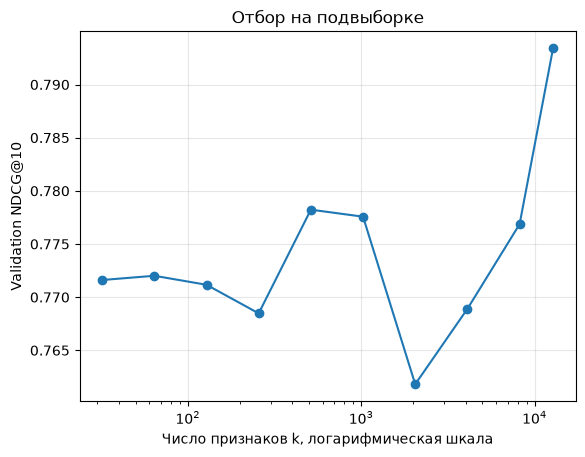

In [4]:
curve = read_table(SELECTION / 'k_curve.csv', required=finished)
if curve is None:
    print('Первые модели еще не завершены.')
else:
    curve = curve.sort_values('k')
    display(curve[['k', 'NDCG@10', 'QueryAUC', 'fit_seconds',
                   'best_iteration', 'tree_count']])
    import matplotlib.pyplot as plt

    ax = curve.plot(x='k', y='NDCG@10', marker='o', logx=True, legend=False)
    ax.set_xlabel('Число признаков k, логарифмическая шкала')
    ax.set_ylabel('Validation NDCG@10')
    ax.set_title('Отбор на подвыборке')
    ax.grid(alpha=0.3)
    plt.show()


## Какие окна остались

Посмотрим на состав набора по сущностям, операциям и длине окна.


In [5]:
selected = read_json(SELECTION / 'selected_features.json', required=finished)
importance = read_table(SELECTION / 'feature_importance.csv', required=finished)
if importance is not None:
    print('Первые 30 признаков по LossFunctionChange на train:')
    display(importance.head(30))
if selected is None:
    print('Итоговый k еще не выбран.')
else:
    print('Выбрано признаков:', selected['selected_k'])
    display(pd.Series(selected['metrics'], name='validation').to_frame())
    if curve is not None and prepared is not None:
        wide = curve.loc[curve['k'] == prepared['candidate_count'], 'NDCG@10']
        if len(wide) == 1:
            gain = (selected['metrics']['NDCG@10'] / wide.iloc[0] - 1) * 100
            print(f'Изменение к широкой модели: {gain:+.3f}% относительно')


Первые 30 признаков по LossFunctionChange на train:


,rank,feature_index,feature,importance
0,1,3196,"Users__TIME_SINCE_LAST(Interactions.end_ts, un...",0.003575
1,2,9406,"UserItem__COUNT(Interactions, Last 29 Days) * ...",0.000351
2,3,6443,UserItem__MAX(Interactions.label) * MEAN(Inter...,0.000283
3,4,370,"Users__MAX(Interactions.track_length_seconds, ...",0.000237
4,5,9633,UserArtist__MAX(Interactions.is_organic) * STD...,0.000220
5,6,3791,"Items__MEAN(Interactions.label, Last 5 Days) *...",0.000210
6,7,12695,UserArtist__MEAN(Interactions.label * track_le...,0.000202
7,8,4688,"Items__MAX(Interactions.label, Last 14 Days) *...",0.000193
8,9,12546,"UserArtist__MEAN(Interactions.label, Last 28 D...",0.000185
9,10,4101,"Items__MEAN(Interactions.label, Last 8 Days) *...",0.000179


Выбрано признаков: 12782


,validation
NDCG@10,0.793415
QueryAUC,0.647891


Изменение к широкой модели: +0.000% относительно


In [6]:
def describe_selected_feature(name):
    """Определить ветвь и окно по имени формулы."""
    if '__' not in name:
        return {'branch': 'исходные атрибуты', 'kind': 'текущий атрибут',
                'window': 'без окна', 'feature': name}
    branch, formula = name.split('__', 1)
    days = sorted(set(int(value) for value in re.findall(r'Last (\d+) Days?', formula)))
    freshness = 'TIME_SINCE_LAST' in formula or 'TIME_SINCE_FIRST' in formula
    window = ', '.join(map(str, days)) + ' дней' if days else 'вся история'
    return {'branch': branch, 'kind': 'свежесть' if freshness else 'агрегат / комбинация',
            'window': window, 'feature': name}


if selected is not None:
    selected_table = pd.DataFrame([
        describe_selected_feature(name) for name in selected['selected_features']])
    display(selected_table.groupby(['branch', 'kind', 'window'], sort=False)
            .size().rename('число признаков').reset_index())
    print('Первые 30 выбранных формул; полный список — в selected_features.json:')
    display(selected_table.head(30))


,branch,kind,window,число признаков
0,исходные атрибуты,текущий атрибут,без окна,2
1,Users,агрегат / комбинация,вся история,103
2,Users,агрегат / комбинация,1 дней,103
3,Users,агрегат / комбинация,2 дней,103
4,Users,агрегат / комбинация,3 дней,103
...,...,...,...,...
124,UserArtist,агрегат / комбинация,27 дней,103
125,UserArtist,агрегат / комбинация,28 дней,103
126,UserArtist,агрегат / комбинация,29 дней,103
127,UserArtist,агрегат / комбинация,30 дней,103


Первые 30 выбранных формул; полный список — в selected_features.json:


,branch,kind,window,feature
0,исходные атрибуты,текущий атрибут,без окна,is_organic
1,исходные атрибуты,текущий атрибут,без окна,track_length_seconds
2,Users,агрегат / комбинация,вся история,Users__COUNT(Interactions)
3,Users,агрегат / комбинация,вся история,Users__MAX(Interactions.is_organic)
4,Users,агрегат / комбинация,вся история,Users__MAX(Interactions.label)
5,Users,агрегат / комбинация,вся история,Users__MAX(Interactions.track_length_seconds)
6,Users,агрегат / комбинация,вся история,Users__MEAN(Interactions.is_organic)
7,Users,агрегат / комбинация,вся история,Users__MEAN(Interactions.label)
8,Users,агрегат / комбинация,вся история,Users__MEAN(Interactions.track_length_seconds)
9,Users,агрегат / комбинация,вся история,Users__MIN(Interactions.is_organic)


## Время и память

`fit_seconds` включает только обучение модели. Подготовка истории,
матриц и важностей считается отдельно. Ниже показано время генерации
по ветвям. `rss_gib` — память в момент записи статуса,
`max_rss_gib` — измеренный пик процесса.

In [7]:
timings = read_json(RUN / 'generation_timings.json', required=finished)
if timings is not None:
    display(pd.DataFrame.from_dict(timings, orient='index')
            .rename_axis('branch').reset_index())
if selected is not None:
    print('Расчет важностей, секунд:', round(selected['importance_seconds'], 3))


,branch,seconds,history_rows,features
0,Users,3.620448,2152042,3195
1,Items,47.154586,13905007,3195
2,UserItem,1.480891,170584,3195
3,UserArtist,1.796300,475795,3195


Расчет важностей, секунд: 0.306


## Как повторяется поиск

В режиме `recompute` первая ячейка запускает поиск с сеткой k выше.
Следующий этап получает новый источник автоматически.
[Порядок расчётов](../../docs/reproduction.md).


### Результат исходного поиска

Полный набор из 12 782 входов получил NDCG@10 0.793415.
Лучший сокращённый вариант top-512 получил 0.778230: потеря 1.914%.
Поиск по LossFunctionChange не сократил набор с сохранением лучшего качества.
Обучение широкой модели заняло 51.73 с.


## Отбор по признакам деревьев

Возьму все входы, использованные в разбиениях широкой модели,
сохранив исходный порядок столбцов. На этом наборе обучу новую модель
с теми же строками и настройками. В исходном запуске получилось 462 входа;
при новом поиске число определяется заново.


In [8]:
workflow.ensure('used')
USED_RUN = workflow.path('used')
used_result = read_json(USED_RUN / 'result.json')
if used_result is None or not used_result.get('completed'):
    print('Переобучение на использованных признаках пока не завершено.')
else:
    used_comparison = pd.read_csv(USED_RUN / 'comparison.csv')
    display(used_comparison)
    print(f"Изменение NDCG@10: {100 * used_result['NDCG_relative_change']:+.3f}% относительно")
    print('Прогнозы исходной модели на 462 входах совпали точно:',
          used_result['original_model_subset_predictions_exact'])
    print('Проверка загрузки новой модели:', used_result['reload_predictions_exact'])


,model,features,NDCG@10,QueryAUC,fit_seconds,tree_count
0,all_features,12782,0.793415,0.647891,51.728320,91
1,used_in_trees_refit,462,0.782910,0.635234,4.127789,118


Изменение NDCG@10: -1.324% относительно
Прогнозы исходной модели на 462 входах совпали точно: True
Проверка загрузки новой модели: True


### Результат исходной проверки

Широкая модель: 12 782 входа, NDCG@10 0.793415, QueryAUC 0.647891, fit 51.73 с.
Повторное обучение: 462 входа, NDCG@10 0.782910, QueryAUC 0.635234, fit 4.13 с.
Потеря NDCG составила 1.324%, меньше, чем у top-512.

У прежней модели прогнозы на использованных входах совпали точно.
При новом обучении получилось 118 деревьев вместо 91.
Далее проверю этот способ сокращения на полном train.


## Полный расчёт выбранных признаков

В исходном запуске использованы 462 входа и все 7 931 435 train-строк.
Validation: 2 882 983 строки. История и матрицы считаются порциями,
validation квантуется по train-порогам.
Параметры те же, что у ручного контроля 1600/80.


In [9]:
workflow.ensure('full')
FULL_RUN = workflow.path('full')
full_result = read_json(FULL_RUN / 'result.json')
if full_result is None or not full_result.get('completed'):
    print('Полный расчет еще не завершен.')
    full_status = read_json(FULL_RUN / 'status.json')
    full_progress = read_json(FULL_RUN / 'progress.json')
    if full_status:
        print('Этап:', full_status.get('stage'))
    if full_progress:
        print(full_progress)
else:
    display(pd.read_csv(FULL_RUN / 'comparison.csv'))
    print('Validation-строк:', full_result['validation_rows'])
    print('Ranking-групп:', full_result['validation_groups'])
    print('Время обучения, мин:', round(full_result['fit_seconds'] / 60, 2))
    print('Подробности:', (FULL_RUN / 'REPORT.md').relative_to(ROOT))


,metric,manual,temporal_dfs_462,difference,relative_loss_percent
0,NDCG@10,0.769794,0.851616,0.081823,-10.629150
1,QueryAUC,0.612847,0.767399,0.154552,-25.218647


Validation-строк: 2882983
Ranking-групп: 56946
Время обучения, мин: 165.59
Подробности: task_1/results/experiment-1/temporal_runs/temporal_full462_20261023_v5/REPORT.md


## Контроли на общей train-подвыборке

Все пять вариантов обучаются на одинаковых 40 000 целых группах.
В исходном запуске это 2 039 017 строк train; полная validation содержит
2 882 983 строки и 56 946 групп.

| Вариант | Признаки |
| --- | --- |
| M-sub | 42 ручных |
| D462-sub | Выбранные автоматические |
| C1 | Автоматические без Users |
| C2a | 42 ручных + 6 пользовательских, без свежести |
| C2b | 42 ручных + все 7 пользовательских |


In [10]:
workflow.ensure('direct-intervals')
CONTROLS_RUN = workflow.path('controls')
controls_status = read_json(CONTROLS_RUN / 'status.json')
controls_selection = read_json(CONTROLS_RUN / 'selection.json')
print('Запуск контролей:', CONTROLS_RUN.name)

if controls_status is None:
    print('Статус пока не записан.')
else:
    print('Этап:', controls_status.get('stage', 'не указан'))
    if controls_status.get('variant'):
        print('Вариант:', controls_status['variant'])
    if controls_status.get('split'):
        print('Часть данных:', controls_status['split'])
    if controls_status.get('error'):
        print('Причина остановки:', controls_status['error'])

if controls_selection is not None:
    display(pd.DataFrame.from_dict({
        split: {'строк': values['rows'], 'групп': values['groups']}
        for split, values in controls_selection.items()
    }, orient='index'))

controls_finished = bool(controls_status and controls_status.get('completed'))
controls_tables_found = False
for controls_title, controls_file in [
    ('Качество и время обучения', 'comparison.csv'),
    ('Парные интервалы разницы NDCG с M-sub', 'bootstrap_summary.csv'),
]:
    controls_table = read_table(CONTROLS_RUN / controls_file)
    if controls_table is not None:
        controls_tables_found = True
        print(controls_title + ('' if controls_finished else ' — предварительная таблица'))
        display(controls_table)
if not controls_tables_found:
    print('Итоговых таблиц пока нет; текущий этап показан выше.')


Запуск контролей: dfs462_controls_20261023_v1
Этап: finished


,строк,групп
train,2039017,40000
val,2882983,56946


Качество и время обучения


,variant,active_features,NDCG@10,QueryAUC,delta_ndcg_vs_M_sub,fit_seconds,tree_count,ci_3d_low,ci_3d_high,ci_4d_low,ci_4d_high
0,M-sub,42,0.767579,0.610282,0.000000,674.441476,629,0.000000,0.000000,0.000000,0.000000
1,D462-sub,462,0.847202,0.757913,0.079623,2297.395830,1510,0.077993,0.081476,0.077959,0.081575
2,C1,330,0.771971,0.616480,0.004392,514.080885,322,0.003740,0.004944,0.003798,0.004976
3,C2a,48,0.797872,0.672982,0.030293,860.195126,876,0.029338,0.031129,0.029357,0.031050
4,C2b,49,0.849833,0.763276,0.082254,1076.524647,1112,0.080694,0.083861,0.080771,0.083789


Парные интервалы разницы NDCG с M-sub


,variant,reference,block_days,replicates,delta_ndcg,ci_low,ci_high,confidence,two_sided,validation_reused
0,M-sub,M-sub,3,20000,0.000000,0.000000,0.000000,0.95,True,True
1,M-sub,M-sub,4,20000,0.000000,0.000000,0.000000,0.95,True,True
2,D462-sub,M-sub,3,20000,0.079623,0.077993,0.081476,0.95,True,True
3,D462-sub,M-sub,4,20000,0.079623,0.077959,0.081575,0.95,True,True
4,C1,M-sub,3,20000,0.004392,0.003740,0.004944,0.95,True,True
5,C1,M-sub,4,20000,0.004392,0.003798,0.004976,0.95,True,True
6,C2a,M-sub,3,20000,0.030293,0.029338,0.031129,0.95,True,True
7,C2a,M-sub,4,20000,0.030293,0.029357,0.031050,0.95,True,True
8,C2b,M-sub,3,20000,0.082254,0.080694,0.083861,0.95,True,True
9,C2b,M-sub,4,20000,0.082254,0.080771,0.083789,0.95,True,True


### Результаты исходных контролей

M-sub получил NDCG@10 0.767579; DFS — 0.847202; без Users — 0.771971.
Ручной набор с шестью пользовательскими признаками получил 0.797872,
со свежестью — 0.849833.

Для C2b − DFS разница +0.002631, для C2b − C2a +0.051961.
Оба размера блока дают положительные интервалы.
Проверка времени ниже объясняет, почему большой прирост требовал пересмотра.


## Оценка прежнего test

Семь сохранённых ранкеров проверены по заранее записанному плану, без fit
и подбора. В test 3 165 779 событий, 61 842 группы, дни 286–301 с единицы.
Ниже отдельно показаны модели общей train-подвыборки и полного train.

In [11]:
if workflow.test_available:
    workflow.ensure('old-test')
    TEST_RUN = workflow.path('old-test')
    for title, filename in [('Общая train-подвыборка', 'comparison_sub.csv'),
                            ('Полный train', 'comparison_full.csv'),
                            ('Парные интервалы test', 'bootstrap_summary.csv')]:
        print(title)
        display(pd.read_csv(TEST_RUN / filename))
else:
    print('Новая оценка test выключена: INCLUDE_TEST=False')


Общая train-подвыборка


,model,family,active_features,NDCG@10,QueryAUC,predict_seconds,tree_count
0,M-sub,sub,42,0.770153,0.605363,0.204143,629
1,D462-sub,sub,462,0.849897,0.758263,0.764401,1510
2,C1,sub,330,0.775418,0.614026,0.323805,322
3,C2a,sub,48,0.801468,0.672599,0.262293,876
4,C2b,sub,49,0.853005,0.763138,0.320294,1112


Полный train


,model,family,active_features,NDCG@10,QueryAUC,predict_seconds,tree_count
0,M-full,full,42,0.772375,0.60823,0.437610,1574
1,D462-full,full,462,0.854219,0.76734,0.746278,1595


Парные интервалы test


,candidate,reference,role,block_days,delta_ndcg,ci_low,ci_high,replicates,seed,confidence,two_sided
0,D462-full,M-full,primary,3,0.081843,0.080714,0.082931,20000,42,0.95,True
1,D462-full,M-full,primary,4,0.081843,0.080857,0.082873,20000,42,0.95,True
2,D462-sub,M-sub,secondary,3,0.079744,0.078505,0.080938,20000,42,0.95,True
3,D462-sub,M-sub,secondary,4,0.079744,0.078648,0.080855,20000,42,0.95,True
4,C1,M-sub,secondary,3,0.005265,0.004686,0.005837,20000,42,0.95,True
5,C1,M-sub,secondary,4,0.005265,0.004767,0.005829,20000,42,0.95,True
6,C2a,M-sub,secondary,3,0.031314,0.030718,0.031866,20000,42,0.95,True
7,C2a,M-sub,secondary,4,0.031314,0.030695,0.031924,20000,42,0.95,True
8,C2b,M-sub,secondary,3,0.082851,0.081894,0.083825,20000,42,0.95,True
9,C2b,M-sub,secondary,4,0.082851,0.081931,0.083814,20000,42,0.95,True


В исходном test полный DFS получил 0.854219 против 0.772375 у ручного
контроля. На общей подвыборке C2b получил 0.853005, DFS — 0.849897.
Эта оценка тоже использовала восстановленный start_ts.


## Проверка восстановленного времени

Секундная фаза свежести определяется текущими длиной трека и долей
прослушивания. При условной перестановке этой фазы NDCG готовой C2b
снизился с 0.849833 до 0.806796, у DFS — с 0.847202 до 0.802563.
Изменение свежести не превышало четырёх секунд.

Это проверка чувствительности готовых моделей. Повторить диагностики можно
этапом `diagnostics` в [общем маршруте](../../docs/reproduction.md).
[Разбор канала утечки](../../docs/start-time-audit.md).


In [12]:
if MODE == 'recompute':
    workflow.ensure('diagnostics')
    diagnostic_runs = [
        PROJECT / f'results/analysis/{RUN_NAME}_permutation',
        PROJECT / f'results/analysis/{RUN_NAME}_dfs_permutation',
    ]
else:
    diagnostic_runs = [
        PROJECT / 'results/analysis/start_ts_phase_permutation_20261024_v1',
        PROJECT / 'results/analysis/start_ts_dfs_phase_permutation_20261024_v1',
    ]
rows = []
for folder in diagnostic_runs:
    result = json.loads((folder / 'result.json').read_text())
    rows.append({'Модель': result['model'],
                 'Исходный NDCG@10': result['original_metrics']['NDCG@10'],
                 'После перестановки': result['permuted_metrics']['NDCG@10'],
                 'Разница': result['delta_ndcg']})
display(pd.DataFrame(rows))


,Модель,Исходный NDCG@10,После перестановки,Разница
0,C2b frozen,0.849833,0.806796,-0.043038
1,D462-sub frozen,0.847202,0.802563,-0.044639


## Сравнение после исправления времени

Заменил время запроса предыдущим строго меньшим timestamp пользователя
и пересчитал все входы. DFS получил NDCG@10 0.804623 на validation
и 0.808187 на прежнем test; расширенные ручные — 0.804896 и 0.809040.
Превосходства над расширенным ручным набором не получилось.

Полный протокол, новые запуски и интервалы — в [итоговом ноутбуке](final-comparison.ipynb).
